In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#Przygotowanie danych
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

dataset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_data = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_size = len(dataset) - 10000
train_data, val_data = random_split(dataset, [train_size, 10000])

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
val_loader = DataLoader(val_data, batch_size=128, shuffle=False)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

def create_model(hidden_layers):
    layers = [nn.Flatten()]
    in_features = 784
    for out_features in hidden_layers:
        layers.append(nn.Linear(in_features, out_features))
        layers.append(nn.ReLU())
        in_features = out_features
    layers.append(nn.Linear(in_features, 10))
    return nn.Sequential(*layers).to(device)

def train_and_evaluate(model, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * xb.size(0)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                loss = criterion(model(xb), yb)
                val_loss += loss.item() * xb.size(0)

        history['train_loss'].append(train_loss / len(train_data))
        history['val_loss'].append(val_loss / len(val_data))

    model.eval()
    test_correct = 0
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = torch.argmax(model(xb), dim=1)
            test_correct += (preds == yb).sum().item()

    test_acc = test_correct / len(test_data)
    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return test_acc, param_count, history

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.8MB/s]


Wyniki:
Wariant 1 (128) | Parametry: 101770 | Accuracy: 0.8788
Wariant 2 (256, 128) | Parametry: 235146 | Accuracy: 0.8781
Wariant 3 (512, 256, 128) | Parametry: 567434 | Accuracy: 0.8834


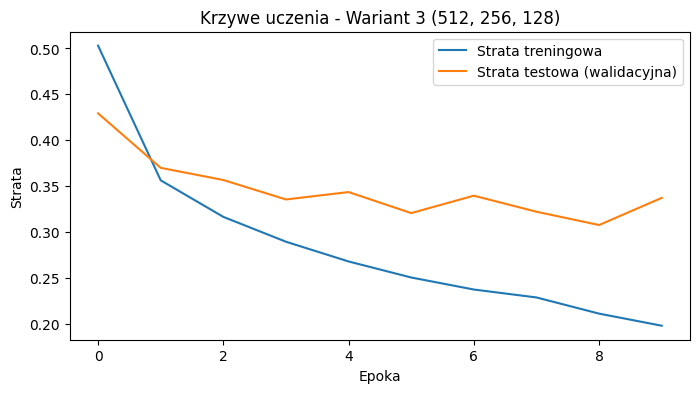

In [4]:
#1. Wytrenuj model bazowy i podaj accuracy na zbiorze testowym.

#2. Zbadaj wpływ architektury — przetestuj co najmniej trzy warianty
#różniące się liczbą i/lub rozmiarem warstw ukrytych (np. (128,) , (256, 128) , (512, 256, 128) ). Dla każdego
#podaj accuracy i liczbę parametrów.

variants = {
    "Wariant 1 (128)": [128],
    "Wariant 2 (256, 128)": [256, 128],
    "Wariant 3 (512, 256, 128)": [512, 256, 128]
}

best_variant_name = None
best_acc = 0.0
best_history = None
best_model = None

print("Wyniki:")
for name, layers in variants.items():
    model = create_model(layers)
    test_acc, param_count, hist = train_and_evaluate(model, epochs=10)
    print(f"{name} | Parametry: {param_count} | Accuracy: {test_acc:.4f}")

    if test_acc > best_acc:
        best_acc = test_acc
        best_variant_name = name
        best_history = hist
        best_model = model

# 3. Dołącz krzywe uczenia (strata trening vs test) dla wariantu najlepszego.
plt.figure(figsize=(8, 4))
plt.plot(best_history['train_loss'], label='Strata treningowa')
plt.plot(best_history['val_loss'], label='Strata testowa (walidacyjna)')
plt.title(f'Krzywe uczenia - {best_variant_name}')
plt.xlabel('Epoka')
plt.ylabel('Strata')
plt.legend()
plt.show()

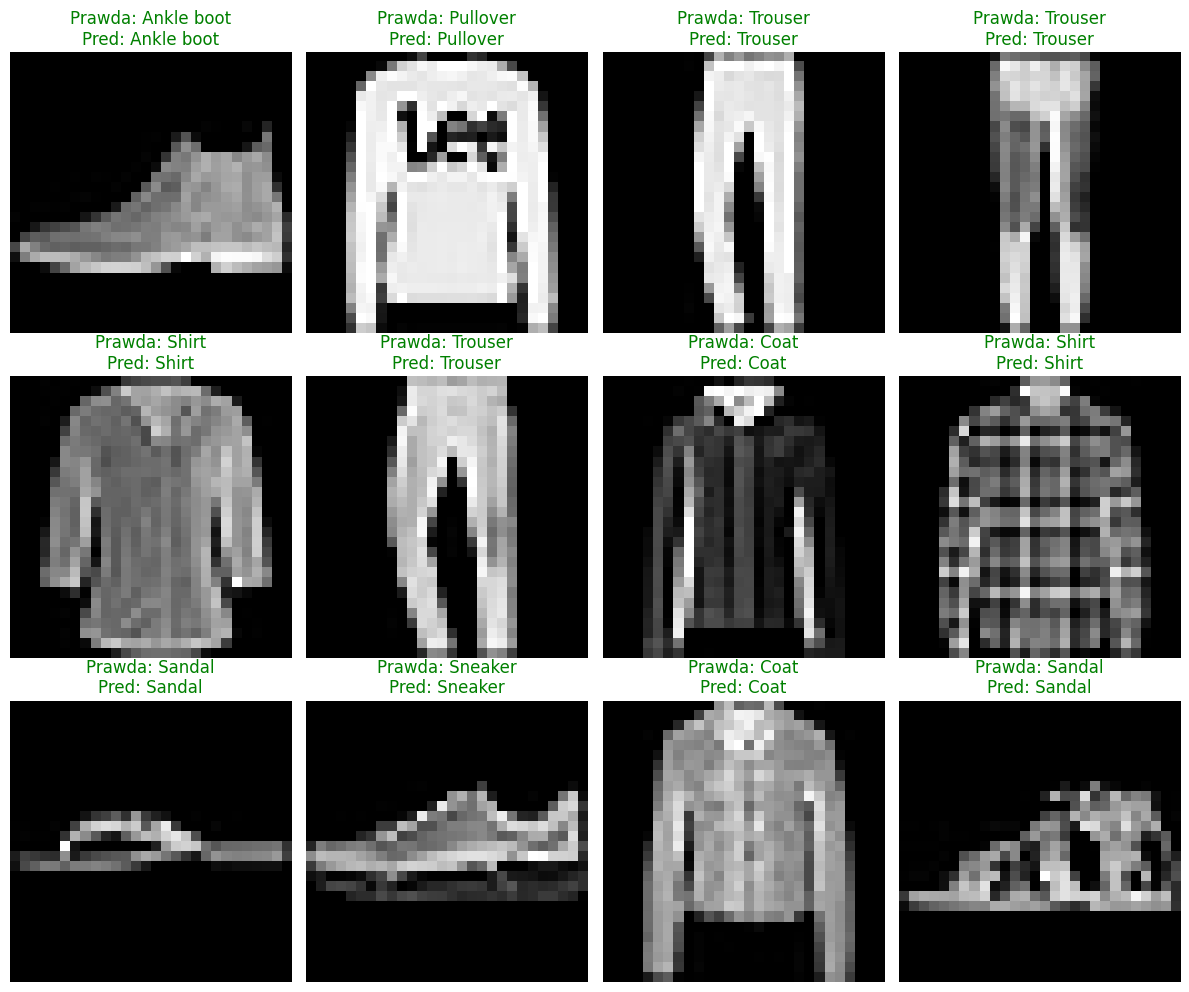

In [5]:
#4. Pokaż siatkę przykładowych predykcji (trafne i błędne) oraz krótko skomentuj, które klasy najczęściej się mylą.
fig, axes = plt.subplots(3, 4, figsize=(12, 10))
axes = axes.flatten()

best_model.eval()
test_iter = iter(test_loader)
images, labels = next(test_iter)
with torch.no_grad():
    preds = torch.argmax(best_model(images.to(device)), dim=1).cpu()

for i in range(12):
    ax = axes[i]
    img = images[i].numpy().squeeze()
    true_class = classes[labels[i]]
    pred_class = classes[preds[i]]

    img = img * 0.3530 + 0.2860

    ax.imshow(img, cmap='gray')
    color = 'green' if true_class == pred_class else 'red'
    ax.set_title(f"Prawda: {true_class}\nPred: {pred_class}", color=color)
    ax.axis('off')

plt.tight_layout()
plt.show()